In [ ]:
from roboflow import Roboflow
import torch

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Training on: {device}")

rf = Roboflow(api_key="1W6S79RDYF5icaq9dh5i") 

print("Downloading Detection dataset...")
dataset_det = rf.workspace("vb-cqemx").project("rugby-r227z").version(1).download("yolo26")

print("Downloading Pose dataset...")
dataset_pose = rf.workspace("rugby-ai").project("rugby-pitch-keypoints-open-source-2").version(2).download("yolov8")

Training on: mps
loading Roboflow workspace...
loading Roboflow project...
loading Roboflow workspace...
loading Roboflow project...


1. DETECTION MODEL TRAINING

In [3]:
from ultralytics import YOLO
import os

print("Starting Detection model training...")

checkpoint_det = "rugby_yolo26/player_detection_e2e/weights/last.pt"

if os.path.exists(checkpoint_det):
    print("Found previous training session. Resuming...")
    model_det = YOLO(checkpoint_det)
    results_det = model_det.train(resume=True) 
else:
    print("Starting training from scratch...")
    model_det = YOLO("yolo26x.pt") 
    results_det = model_det.train(
        data=f"{dataset_det.location}/data.yaml",
        epochs=50, 
        imgsz=640,
        batch=-1,
        device="mps",              
        save=True,
        cache = True,
        workers = 8,
        save_period=5,
        project="rugby_yolo26",
        name="player_detection_e2e"
    )

print("Completed training Detection model!")

Starting Detection model training...
Starting training from scratch...
Ultralytics 8.4.48 🚀 Python-3.13.12 torch-2.11.0 MPS (Apple M4 Max)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=True, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/tntran2/Mllm-Rugby-Analysis/Rugby-1/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26x.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=player_detection_e2e-2, n

KeyboardInterrupt: 

2. POSE MODEL TRAINING

In [3]:
from ultralytics import YOLO
import os

print("Starting Pose model training...")

checkpoint_pose = "rugby_yolo26/pitch_keypoints_fix/weights/last.pt"

if os.path.exists(checkpoint_pose):
    print("Found previous training session. Resuming...")
    model_pose = YOLO(checkpoint_pose)
    results_pose = model_pose.train(resume=True)
else:
    print("Starting training from scratch with 46 keypoints architecture...")
    
    model_pose = YOLO("yolo26x-pose.yaml").load("yolo26x-pose.pt") 
    
    results_pose = model_pose.train(
        data=f"{dataset_pose.location}/data.yaml",
        epochs=50,
        imgsz=640,
        batch=4,
        device="mps",
        fliplr=0.0,
        save=True,
        save_period=5,
        project="rugby_yolo26",
        name="pitch_keypoints_fix"
    )

print("Completed training Pose model!")

Starting Pose model training...
Starting training from scratch with 46 keypoints architecture...
Transferred 1251/1263 items from pretrained weights
Ultralytics 8.4.48 🚀 Python-3.13.12 torch-2.11.0 MPS (Apple M4 Max)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/tntran2/Mllm-Rugby-Analysis/Rugby-Pitch-Keypoints-Open-Source-2-2/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.

3. DETECTION EVALUATION

In [ ]:
best_det_model = YOLO("rugby_yolo26/player_detection_e2e/weights/best.pt")

print("Evaluating Detection model...")
metrics_det = best_det_model.val(device="mps")

print(f"mAP50 (Box): {metrics_det.box.map50:.3f}")
print(f"mAP50-95 (Box): {metrics_det.box.map:.3f}")

4. POSE EVALUATION

In [ ]:
best_pose_model = YOLO("rugby_yolo26/pitch_keypoints/weights/best.pt")

print("Evaluating Pose model...")
metrics_pose = best_pose_model.val(device="mps")

print(f"mAP50 (Box Sân): {metrics_pose.box.map50:.3f}")
print(f"mAP50 (Điểm mốc - Pose): {metrics_pose.pose.map50:.3f}")

# Inference yolov26

In [1]:
from ultralytics import YOLO

model = YOLO("yolo26x.pt") 

results = model.predict(
    source="Plan1_First_half.mp4", 
    save=True,                                  
    device="mps"                                 
)

print("Completed running baseline model!")


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/63376) /Users/tntran2/Mllm-Rugby-Analysis/Plan1_First_half.mp4: 384x640 18 persons, 92.7ms
video 1/1 (frame 2/63376) /Users/tntran2/Mllm-Rugby-Analysis/Plan1_First_half.mp4: 384x640 17 persons, 30.6ms
video 1/1 (frame 3/63376) /Users/tntran2/Mllm-Rugby-Analysis/Plan1_First_half.mp4: 384x640 16 persons, 18.1ms
video 1/1 (frame 4/63376) /Users/tntran2/Mllm-Rugby-Analysis/Plan1_First_half.mp4: 384x640 17 persons, 18.0ms
video 1/1 (frame 5

Phát hiện vạch C1     tại Pixel( 715,  271) - Tự tin cao nhất: 0.53
Phát hiện vạch T1     tại Pixel( 845,  286) - Tự tin cao nhất: 0.57
Phát hiện vạch 22_1   tại Pixel( 851,  287) - Tự tin cao nhất: 0.58
Phát hiện vạch 22_2   tại Pixel(1317,  360) - Tự tin cao nhất: 0.26
Phát hiện vạch 22_3   tại Pixel(1221,  415) - Tự tin cao nhất: 0.41
Phát hiện vạch 22_4   tại Pixel( 562,  779) - Tự tin cao nhất: 0.16
Phát hiện vạch 5_1    tại Pixel( 900,  316) - Tự tin cao nhất: 0.57
Phát hiện vạch 5_2    tại Pixel( 771,  364) - Tự tin cao nhất: 0.58
Phát hiện vạch P1     tại Pixel( 377,  446) - Tự tin cao nhất: 0.21
Phát hiện vạch P2     tại Pixel( 267,  485) - Tự tin cao nhất: 0.10

✅ Image saved successfully at: result.jpg


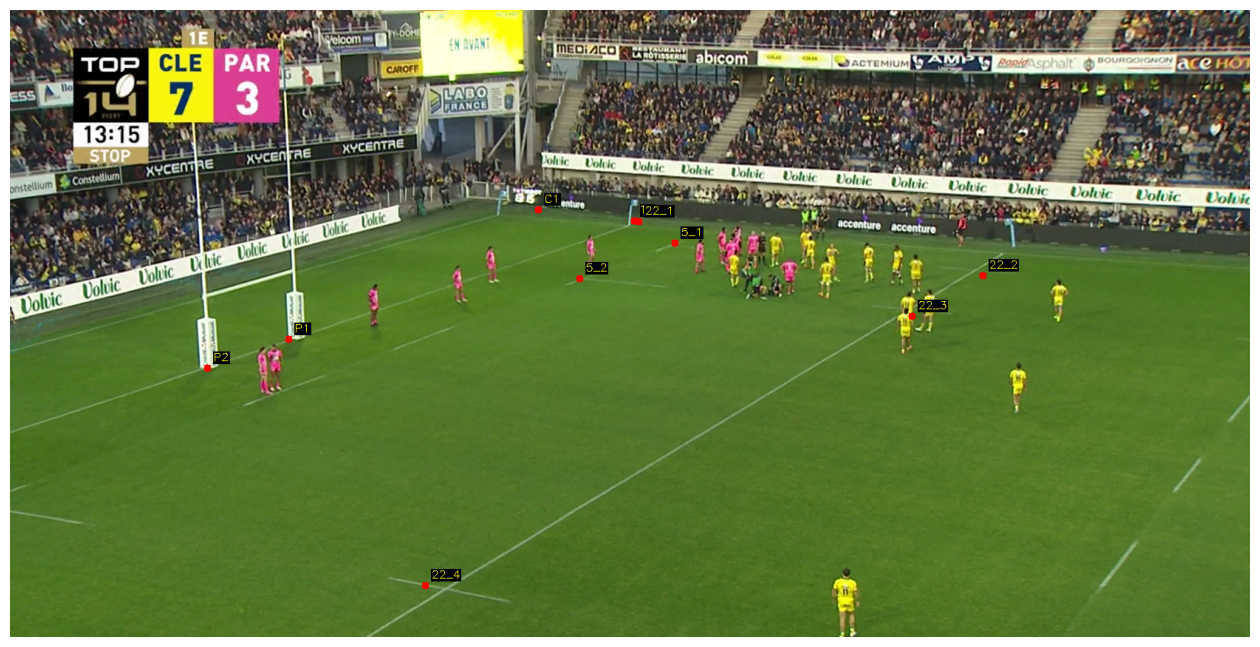

In [44]:
import cv2
import numpy as np
from ultralytics import YOLO
import matplotlib.pyplot as plt

PITCH_DICTIONARY = {
    # --- CORNERS ---
    0: "C1_L",
    1: "C2_L",
    8: "C1_R",
    9: "C2_R",

    # --- TRY LINES ---
    2: "T2_L",
    3: "T1_L",
    6: "T1_R",
    10: "T2_R",

    # --- LEFT 22m ---
    4: "22_1_L",
    11: "22_2_L",
    12: "22_3_L",
    13: "22_4_L",
    14: "22_5_L",
    15: "22_6_L",

    # --- HALFWAY ---
    5: "H1",
    16: "H2",
    17: "H3",
    18: "H4",
    19: "H5",
    20: "H6",

    # --- RIGHT 22m ---
    21: "22_2_R",
    22: "22_3_R",
    23: "22_4_R",
    24: "22_5_R",
    25: "22_6_R",
    7: "22_1_R",

    # --- LEFT 5m ---
    26: "5_1_L",
    27: "5_2_L",
    28: "5_3_L",
    29: "5_4_L",

    # --- LEFT 10m ---
    30: "10_1_L",
    31: "10_2_L",
    32: "10_3_L",
    33: "10_4_L",

    # --- RIGHT 10m ---
    34: "10_1_R",
    35: "10_2_R",
    36: "10_3_R",
    37: "10_4_R",

    # --- RIGHT 5m ---
    38: "5_1_R",
    39: "5_2_R",
    40: "5_3_R",
    41: "5_4_R",

    # --- POSTS ---
    42: "P1_L",
    43: "P2_L",
    44: "P1_R",
    45: "P2_R",
}

def analyze_and_draw_pitch(model_path, image_path, conf_threshold=0.5):
    # 1. Load mô hình & Ảnh
    model = YOLO(model_path)
    img = cv2.imread(image_path)
    
    if img is None:
        print("Cannot find the image! Please check the path again.")
        return

    # 2. Chạy dự đoán
    results = model.predict(source=image_path, conf=conf_threshold, verbose=False)
    
    # 3. Lọc và gộp các điểm đối xứng (NMS Keypoints)
    merged_points = {}
    
    for result in results:
        if result.keypoints is not None:
            kpts_array = result.keypoints.data[0].cpu().numpy()
            
            for point_id, kpt in enumerate(kpts_array):
                x, y, conf = kpt
                
                if conf > conf_threshold:
                    raw_name = PITCH_DICTIONARY.get(point_id, f"Unknown_{point_id}")
                    
                    # Cắt bỏ hậu tố _L và _R để tạo tên gốc (Ví dụ: "22_3_L" -> "22_3")
                    base_name = raw_name.replace("_L", "").replace("_R", "")
                    
                    # Nếu vạch này chưa được lưu, HOẶC điểm mới có độ tự tin cao hơn điểm cũ thì cập nhật
                    if base_name not in merged_points or conf > merged_points[base_name]['conf']:
                        merged_points[base_name] = {
                            'x': int(x),
                            'y': int(y),
                            'conf': float(conf)
                        }

    # 4. Vẽ các điểm đã gộp lên ảnh
    for base_name, data in merged_points.items():
        x_px, y_px = data['x'], data['y']
        
        # Vẽ chấm tròn (Màu đỏ, tô đặc)
        cv2.circle(img, (x_px, y_px), radius=5, color=(0, 0, 255), thickness=-1)
        
        # Chỉ hiển thị tên vạch rút gọn
        text = f"{base_name}"
        font = cv2.FONT_HERSHEY_SIMPLEX
        font_scale = 0.5
        thickness = 1
        (text_w, text_h), _ = cv2.getTextSize(text, font, font_scale, thickness)
        
        # Vẽ hộp nền đen chống đè chữ (thickness=-1 để tô đen đặc)
        cv2.rectangle(img, (x_px + 8, y_px - 10 - text_h), (x_px + 8 + text_w, y_px - 6), (0, 0, 0), -1)
        cv2.putText(img, text, (x_px + 8, y_px - 10), font, font_scale, (0, 255, 255), thickness)
        
        print(f"Phát hiện vạch {text:<6} tại Pixel({x_px:>4}, {y_px:>4}) - Tự tin cao nhất: {data['conf']:.2f}")

    # 5. Hiển thị bằng Matplotlib
    output_path = "result.jpg"
    cv2.imwrite(output_path, img)
    print(f"\n✅ Image saved successfully at: {output_path}")

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(16, 10)) 
    plt.imshow(img_rgb)
    plt.axis('off') 
    plt.show()

# ==========================================
# CHẠY THỰC THI
# ==========================================
if __name__ == "__main__":
    MY_MODEL = "weights.pt" # Trỏ tới file best.pt của YOLO26x
    MY_IMAGE = "Screenshot 2026-05-12 163526.png"  # Trỏ tới ảnh broadcast của bạn
    
    analyze_and_draw_pitch(MY_MODEL, MY_IMAGE, conf_threshold=0.05)